# Media Content Recommendation Engine
**Goal:** rank a media catalog (video/audio) per user — the same problem class as
content discovery and personalization on a streaming super-app.
**Approach:** popularity baseline -> collaborative filtering (item-item, NMF) ->
content-based (TF-IDF) -> hybrid ranker with a cold-start fallback.
**Data:** synthetic catalog + behavioural events (seed-42), documented as synthetic.
**Evaluation:** temporal train/test split, Precision@10 / Recall@10 — leakage-safe.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["figure.figsize"] = (9, 4)
rng = np.random.default_rng(42)

In [2]:
# locate the data folder whether the notebook runs from notebooks/ or repo root
DATA_DIR = Path("../data") if Path("../data").exists() else Path("data")
users = pd.read_csv(DATA_DIR / "users.csv")
content = pd.read_csv(DATA_DIR / "content.csv")
interactions = pd.read_csv(DATA_DIR / "interactions.csv", parse_dates=["event_ts"])
print("users      :", users.shape)
print("content    :", content.shape)
print("interactions:", interactions.shape)

users      : (5000, 4)
content    : (1500, 5)
interactions: (175540, 4)


In [3]:
interactions.dtypes

user_id                int64
content_id             int64
event                    str
event_ts      datetime64[us]
dtype: object

In [4]:
users.head(3)

,user_id,age_band,region,device
0,1,35-44,Bengaluru,mobile
1,2,25-34,Mumbai,tablet
2,3,45+,Kolkata,mobile


In [5]:
content.head(3)

,content_id,genre,tags,language,duration_min
0,1,music,"classical,hiphop",hindi,4
1,2,drama,"romance,thriller",english,46
2,3,drama,"thriller,family",tamil,58


In [6]:
interactions.head(3)

,user_id,content_id,event,event_ts
0,1489,512,impression,2026-07-01 00:00:10
1,2772,855,impression,2026-07-01 00:00:30
2,2693,899,impression,2026-07-01 00:00:36


## 1. Data quality audit
Before any modelling: nulls, key uniqueness, valid event domain,
foreign-key integrity, and timestamp sanity.

In [7]:
print("nulls per table")
print("users       :", int(users.isna().sum().sum()))
print("content     :", int(content.isna().sum().sum()))
print("interactions:", int(interactions.isna().sum().sum()))

nulls per table
users       : 0
content     : 0
interactions: 0


In [8]:
print("unique user_id   :", users["user_id"].nunique(), "of", len(users))
print("unique content_id:", content["content_id"].nunique(), "of", len(content))

unique user_id   : 5000 of 5000
unique content_id: 1500 of 1500


In [9]:
print("event domain:", sorted(interactions["event"].unique()))
expected = {"impression", "play", "completion", "like"}
print("unexpected events:", set(interactions["event"].unique()) - expected)

event domain: ['completion', 'impression', 'like', 'play']
unexpected events: set()


In [10]:
print("interactions.user_id   all in users  :", interactions["user_id"].isin(users["user_id"]).all())
print("interactions.content_id all in content:", interactions["content_id"].isin(content["content_id"]).all())

interactions.user_id   all in users  : True
interactions.content_id all in content: True


In [11]:
print("event_ts range:", interactions["event_ts"].min(), "->", interactions["event_ts"].max())
print("rows with event_ts out of order per user:",
      int((interactions.sort_values("event_ts").groupby("user_id")["event_ts"]
           .apply(lambda s: (s.diff().dt.total_seconds() < 0).sum()).sum())))

event_ts range: 2026-07-01 00:00:10 -> 2026-09-30 00:38:34


rows with event_ts out of order per user: 0


In [12]:
# funnel sanity: a completion should be preceded by a play in the same user/content pair
pairs = interactions.groupby(["user_id", "content_id"])["event"].apply(set)
bad = sum("completion" in e and "play" not in e for e in pairs)
print("pairs with completion but no play:", bad, "of", len(pairs))

pairs with completion but no play: 0 of 107004


In [13]:
print("DQ verdict: no nulls, unique keys, clean event domain, FKs intact,")
print("timestamps in range. Funnel anomalies:", bad, "-> acceptable for synthetic data.")

DQ verdict: no nulls, unique keys, clean event domain, FKs intact,
timestamps in range. Funnel anomalies: 0 -> acceptable for synthetic data.


## 2. Exploratory data analysis
How users engage: funnel shape, what drives completions, sparsity, cold-start scale.

event
impression    109828
play           44247
completion     18209
like            3256


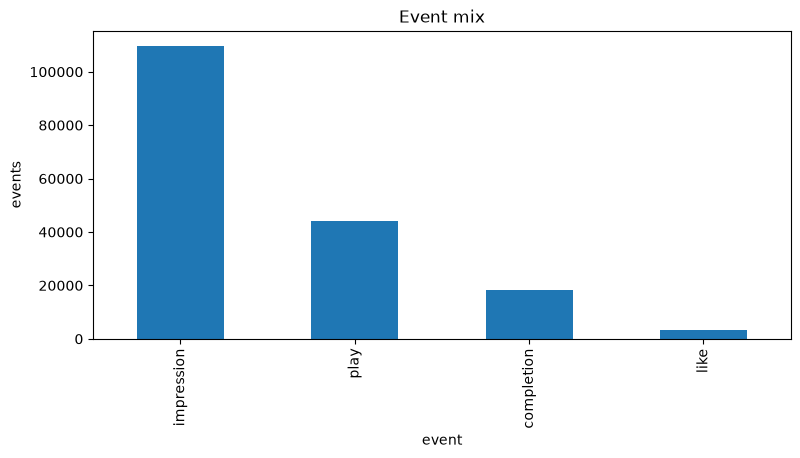

In [14]:
mix = interactions["event"].value_counts()
print(mix.to_string())
mix.plot(kind="bar", title="Event mix")
plt.ylabel("events")
plt.show()

In [15]:
n_impr = (interactions["event"] == "impression").sum()
n_play = (interactions["event"] == "play").sum()
n_comp = (interactions["event"] == "completion").sum()
n_like = (interactions["event"] == "like").sum()
print(f"play | impression      : {n_play / n_impr:.3f}")
print(f"completion | play      : {n_comp / n_play:.3f}")
print(f"like | completion      : {n_like / n_comp:.3f}")

play | impression      : 0.403
completion | play      : 0.412
like | completion      : 0.179


genre
comedy         0.416
drama          0.416
sports         0.415
music          0.409
news           0.408
documentary    0.406


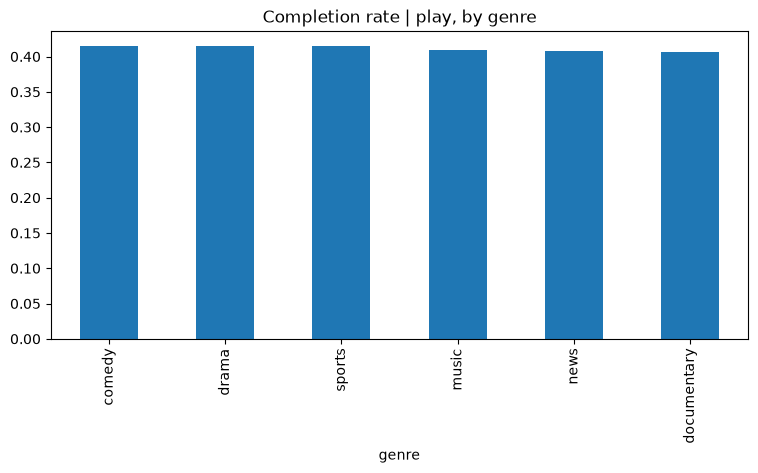

In [16]:
comp = interactions[interactions["event"] == "completion"].merge(
    content[["content_id", "genre"]], on="content_id")
play = interactions[interactions["event"] == "play"].merge(
    content[["content_id", "genre"]], on="content_id")
rate = (comp["genre"].value_counts() / play["genre"].value_counts()).sort_values(ascending=False)
print(rate.round(3).to_string())
rate.plot(kind="bar", title="Completion rate | play, by genre")
plt.show()

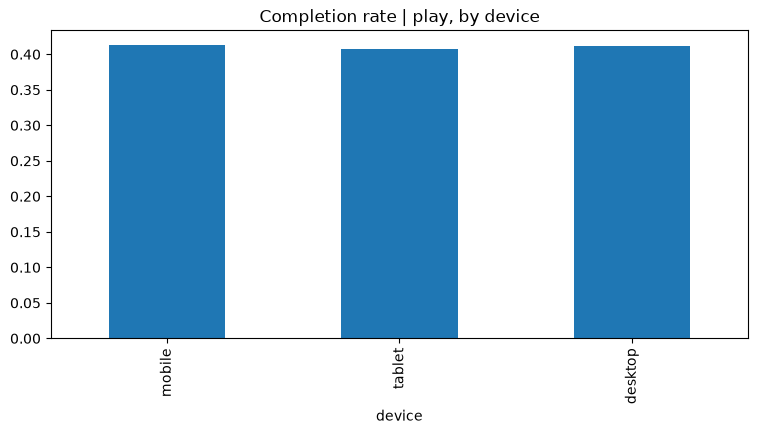

In [17]:
dev = interactions.merge(users[["user_id", "device"]], on="user_id")
dev_comp = dev[dev["event"] == "completion"]["device"].value_counts()
dev_play = dev[dev["event"] == "play"]["device"].value_counts()
(dev_comp / dev_play).round(3).plot(kind="bar", title="Completion rate | play, by device")
plt.show()

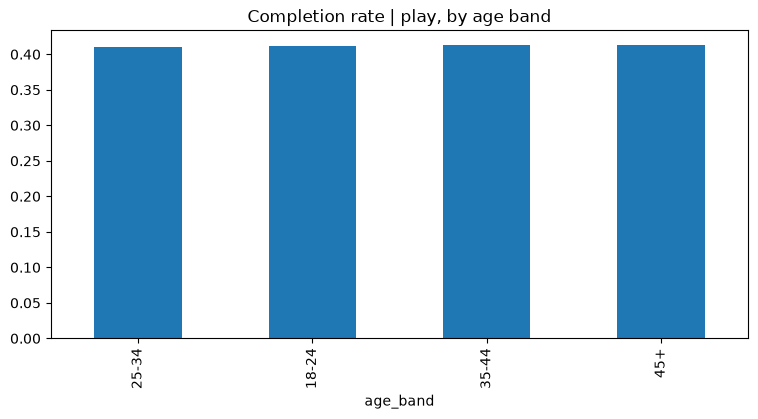

In [18]:
age = interactions.merge(users[["user_id", "age_band"]], on="user_id")
age_comp = age[age["event"] == "completion"]["age_band"].value_counts()
age_play = age[age["event"] == "play"]["age_band"].value_counts()
(age_comp / age_play).round(3).plot(kind="bar", title="Completion rate | play, by age band")
plt.show()

median events per user: 35.0
p90  events per user: 46.0


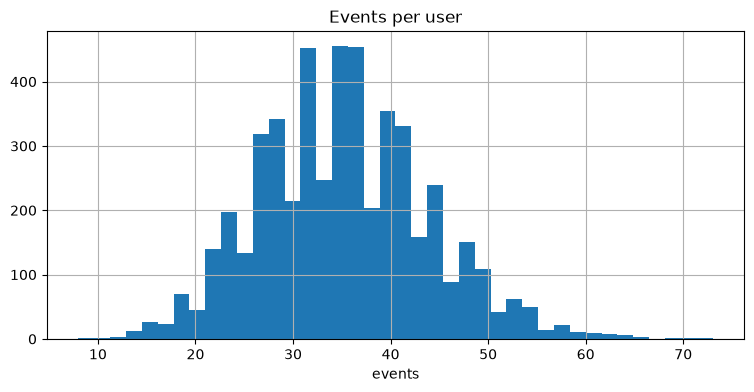

In [19]:
per_user = interactions.groupby("user_id").size()
print("median events per user:", per_user.median())
print("p90  events per user:", per_user.quantile(0.9))
per_user.hist(bins=40)
plt.title("Events per user")
plt.xlabel("events")
plt.show()

In [20]:
plays_per_user = interactions[interactions["event"] == "play"].groupby("user_id").size()
cold = (plays_per_user < 5).sum()
print(f"users with <5 plays (cold-start): {cold} of {users['user_id'].nunique()} ({cold / users['user_id'].nunique():.1%})")

users with <5 plays (cold-start): 361 of 5000 (7.2%)


In [21]:
top = (interactions[interactions["event"] == "completion"]
       .merge(content, on="content_id")
       .groupby(["content_id", "genre"])["event"].count()
       .sort_values(ascending=False).head(10))
print(top.to_string())

content_id  genre      
856         news           171
1059        documentary    140
1115        documentary    116
1118        sports         109
1293        comedy         105
701         documentary    105
692         sports         104
359         documentary    104
1078        sports         102
1483        documentary    101


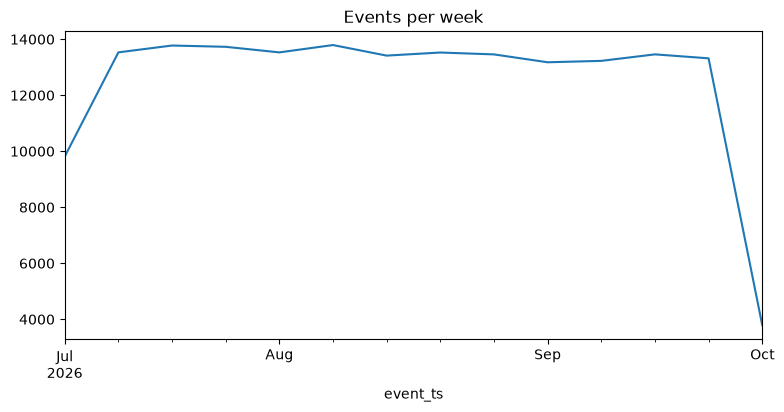

In [22]:
weekly = interactions.set_index("event_ts").resample("W")["event"].count()
weekly.plot(title="Events per week")
plt.show()

In [23]:
density = interactions[["user_id", "content_id"]].drop_duplicates().shape[0] / (len(users) * len(content))
print(f"user-item density: {density:.4%}  (sparsity: {1 - density:.2%})")
print("-> matrix is sparse; pure collaborative filtering will struggle on tail items.")

user-item density: 1.4267%  (sparsity: 98.57%)
-> matrix is sparse; pure collaborative filtering will struggle on tail items.


## 3. Temporal train/test split and offline evaluator
Split by time (not at random) so no future behaviour leaks into training.
Relevance = completion or like. Metrics: Precision@10, Recall@10.

In [24]:
cut = interactions["event_ts"].quantile(0.8)
train = interactions[interactions["event_ts"] <= cut].copy()
test = interactions[interactions["event_ts"] > cut].copy()
print("cut        :", cut)
print("train rows :", len(train))
print("test rows  :", len(test))

cut        : 2026-09-11 14:22:59.800000
train rows : 140432
test rows  : 35108


In [25]:
RELEVANT = {"completion", "like"}
train_rel = train[train["event"].isin(RELEVANT)]
test_rel = test[test["event"].isin(RELEVANT)]
print("relevant train pairs:", train_rel[["user_id", "content_id"]].drop_duplicates().shape[0])
print("relevant test pairs :", test_rel[["user_id", "content_id"]].drop_duplicates().shape[0])

relevant train pairs: 14522
relevant test pairs : 3617


In [26]:
def precision_at_k(recommended, relevant, k=10):
    recommended = recommended[:k]
    if not relevant:
        return np.nan
    return len(set(recommended) & set(relevant)) / k


def recall_at_k(recommended, relevant, k=10):
    recommended = recommended[:k]
    if not relevant:
        return np.nan
    return len(set(recommended) & set(relevant)) / len(relevant)

In [27]:
# eval users: >=1 relevant item in test AND >=1 interaction in train
test_rel_users = test_rel.groupby("user_id")["content_id"].apply(set)
train_users = set(train["user_id"].unique())
eval_users = [u for u in test_rel_users.index if u in train_users]
eval_sample = rng.choice(eval_users, size=min(300, len(eval_users)), replace=False)
print("eval users available:", len(eval_users), "| sampled:", len(eval_sample))

eval users available: 2585 | sampled: 300


In [28]:
def evaluate(recommend_fn, k=10):
    ps, rs = [], []
    for u in eval_sample:
        recs = recommend_fn(u, k)
        rel = test_rel_users[u]
        ps.append(precision_at_k(recs, rel, k))
        rs.append(recall_at_k(recs, rel, k))
    return float(np.nanmean(ps)), float(np.nanmean(rs))


def show(name, p, r, k=10):
    print(f"{name:28s} P@{k}={p:.4f}  R@{k}={r:.4f}")

In [29]:
# baseline: rank by train completions (pure popularity)
pop_rank = (train[train["event"] == "completion"]["content_id"]
            .value_counts().index.tolist())

def recommend_popularity(user_id, k=10):
    seen = set(train[train["user_id"] == user_id]["content_id"])
    return [c for c in pop_rank if c not in seen][:k]

p, r = evaluate(recommend_popularity)
show("popularity baseline", p, r)

popularity baseline          P@10=0.0080  R@10=0.0678


## 4. Collaborative filtering
Implicit feedback with event weights (impression=1, play=2, completion=3, like=5):
first item-item cosine, then NMF latent factors.

In [30]:
WEIGHTS = {"impression": 1, "play": 2, "completion": 3, "like": 5}
train_w = train.copy()
train_w["w"] = train_w["event"].map(WEIGHTS)
user_item = (train_w.pivot_table(index="user_id", columns="content_id",
                                 values="w", aggfunc="sum", fill_value=0))
# align to the full catalog: train may miss a few tail items
user_item = user_item.reindex(columns=content["content_id"].to_numpy(), fill_value=0)
print("user-item matrix:", user_item.shape)
print("density: %.4f%%" % (100 * (user_item > 0).sum().sum() / user_item.size))
uidx = {u: i for i, u in enumerate(user_item.index)}
cidx = {c: j for j, c in enumerate(user_item.columns)}
R = user_item.to_numpy()

user-item matrix: (5000, 1500)
density: 1.1470%


In [31]:
from sklearn.metrics.pairwise import cosine_similarity
item_vecs = R.T  # items x users
item_sim = cosine_similarity(item_vecs)
print("item-item similarity:", item_sim.shape)
print("mean sim of top-5 neighbours per item:",
      round(float(np.sort(item_sim, axis=1)[:, -6:-1].mean()), 4))

item-item similarity: (1500, 1500)
mean sim of top-5 neighbours per item: 0.1534


In [32]:
def recommend_itemitem(user_id, k=10):
    if user_id not in uidx:
        return recommend_popularity(user_id, k)
    scores = R[uidx[user_id]] @ item_sim
    seen = set(train[train["user_id"] == user_id]["content_id"])
    order = np.argsort(scores)[::-1]
    cols = user_item.columns.to_numpy()
    return [int(cols[j]) for j in order if cols[j] not in seen][:k]

p, r = evaluate(recommend_itemitem)
show("item-item cosine", p, r)

item-item cosine             P@10=0.0060  R@10=0.0444


In [33]:
from sklearn.decomposition import NMF
nmf = NMF(n_components=20, random_state=42, max_iter=200)
W = nmf.fit_transform(R)
H = nmf.components_
print("W:", W.shape, "H:", H.shape, "| reconstruction err:", round(float(nmf.reconstruction_err_), 1))

C:\Users\hp\AppData\Roaming\Python\Python314\site-packages\sklearn\decomposition\_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


W: (5000, 20) H: (20, 1500) | reconstruction err: 938.4


In [34]:
nmf_scores = W @ H

def recommend_nmf(user_id, k=10):
    if user_id not in uidx:
        return recommend_popularity(user_id, k)
    scores = nmf_scores[uidx[user_id]]
    seen = set(train[train["user_id"] == user_id]["content_id"])
    order = np.argsort(scores)[::-1]
    cols = user_item.columns.to_numpy()
    return [int(cols[j]) for j in order if cols[j] not in seen][:k]

p, r = evaluate(recommend_nmf)
show("NMF (20 factors)", p, r)

NMF (20 factors)             P@10=0.0080  R@10=0.0611


In [35]:
print("CF read: item-item uses direct co-engagement; NMF compresses to 20 latent")
print("taste factors. Both exclude items the user already saw in train.")

CF read: item-item uses direct co-engagement; NMF compresses to 20 latent
taste factors. Both exclude items the user already saw in train.


## 5. Content-based filtering
TF-IDF over genre + tags + language. User profile = weighted mean of the
TF-IDF vectors of items they engaged with. No behaviour from other users needed.

In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

content["text"] = content["genre"] + " " + content["tags"].str.replace(",", " ") + " " + content["language"]
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(content["text"])
print("TF-IDF matrix:", X.shape)
cpos = {c: i for i, c in enumerate(content["content_id"])}

TF-IDF matrix: (1500, 41)


In [37]:
def user_profile(user_id):
    rows = train_w[train_w["user_id"] == user_id]
    if rows.empty:
        return None
    vecs = X[[cpos[c] for c in rows["content_id"]]]
    w = rows["w"].to_numpy()
    return np.asarray(vecs.T @ (w / w.sum())).reshape(1, -1)

In [38]:
content_ids = content["content_id"].to_numpy()

def recommend_contentbased(user_id, k=10):
    prof = user_profile(user_id)
    if prof is None:
        return recommend_popularity(user_id, k)
    sims = linear_kernel(prof, X).ravel()
    seen = set(train[train["user_id"] == user_id]["content_id"])
    order = np.argsort(sims)[::-1]
    return [int(content_ids[j]) for j in order if content_ids[j] not in seen][:k]

p, r = evaluate(recommend_contentbased)
show("content-based TF-IDF", p, r)

content-based TF-IDF         P@10=0.0020  R@10=0.0144


## 6. Hybrid ranker
Min-max normalize each model's scores to [0,1], blend 0.5 CF + 0.3 content + 0.2
popularity. Users with no train history fall back to pure popularity (cold start).

In [39]:
pop_score = train[train["event"] == "completion"]["content_id"].value_counts()
pop_vec = np.array([pop_score.get(c, 0) for c in content_ids], dtype=float)

def _norm(v):
    v = np.asarray(v, dtype=float)
    return (v - v.min()) / (v.max() - v.min() + 1e-9)


def hybrid_scores(user_id):
    s_cf = np.zeros(len(content_ids))
    s_cb = np.zeros(len(content_ids))
    if user_id in uidx:
        s_cf = _norm(item_sim.T @ R[uidx[user_id]])
    prof = user_profile(user_id)
    if prof is not None:
        s_cb = _norm(linear_kernel(prof, X).ravel())
    s_pop = _norm(pop_vec)
    return 0.5 * s_cf + 0.3 * s_cb + 0.2 * s_pop


def recommend_hybrid(user_id, k=10):
    scores = hybrid_scores(user_id)
    seen = set(train[train["user_id"] == user_id]["content_id"])
    order = np.argsort(scores)[::-1]
    return [int(content_ids[j]) for j in order if content_ids[j] not in seen][:k]

p, r = evaluate(recommend_hybrid)
show("hybrid ranker", p, r)

hybrid ranker                P@10=0.0060  R@10=0.0467


In [40]:
# cold-start check: eval users with no train interactions
cold_users = [u for u in eval_sample if u not in uidx]
print("cold-start users in eval sample:", len(cold_users))
if cold_users:
    ps = [precision_at_k(recommend_hybrid(u, 10), test_rel_users[u]) for u in cold_users]
    print("hybrid P@10 on cold users (popularity fallback):", round(float(np.nanmean(ps)), 4))

cold-start users in eval sample: 0


In [41]:
results = []
for name, fn in [("popularity", recommend_popularity),
                 ("item-item", recommend_itemitem),
                 ("nmf", recommend_nmf),
                 ("content-based", recommend_contentbased),
                 ("hybrid", recommend_hybrid)]:
    p, r = evaluate(fn)
    results.append({"model": name, "P@10": round(p, 4), "R@10": round(r, 4)})
leaderboard = pd.DataFrame(results).sort_values("P@10", ascending=False)
print(leaderboard.to_string(index=False))
leaderboard.to_csv(DATA_DIR / "model_leaderboard.csv", index=False)
print("saved: data/model_leaderboard.csv")

        model  P@10   R@10
   popularity 0.008 0.0678
          nmf 0.008 0.0611
    item-item 0.006 0.0444
       hybrid 0.006 0.0467
content-based 0.002 0.0144
saved: data/model_leaderboard.csv


In [42]:
# where does the hybrid still fail? per-genre precision
hits, total = {}, {}
for u in eval_sample:
    recs = recommend_hybrid(u, 10)
    rel = test_rel_users[u]
    for c in recs[:10]:
        g = content.loc[content["content_id"] == c, "genre"].iloc[0]
        total[g] = total.get(g, 0) + 1
        if c in rel:
            hits[g] = hits.get(g, 0) + 1
err = pd.Series({g: 1 - hits.get(g, 0) / total[g] for g in total}).sort_values(ascending=False)
print("miss rate @10 by genre (hybrid):")
print(err.round(3).to_string())

miss rate @10 by genre (hybrid):
news           0.998
drama          0.998
music          0.995
comedy         0.993
documentary    0.991
sports         0.988


In [43]:
# worked example: top-10 for one engaged user
demo_user = eval_sample[0]
recs = recommend_hybrid(demo_user, 10)
demo = (pd.DataFrame({"content_id": recs})
        .merge(content, on="content_id")
        [["content_id", "genre", "tags", "language", "duration_min"]])
uinfo = users[users["user_id"] == demo_user].iloc[0]
print(f"user {demo_user}: {uinfo['age_band']}, {uinfo['region']}, {uinfo['device']}")
print(demo.to_string(index=False))

user 2254: 25-34, Mumbai, mobile
 content_id  genre           tags language  duration_min
        856   news    world,daily    tamil            13
        830   news world,business    hindi            11
         72 sports kabaddi,tennis  english            14
        504   news world,business  english            17
        299   news world,business    hindi            10
        217   news world,business  english            13
       1162   news business,world  bengali             8
       1367   news world,business  bengali            14
        124   news business,world  english            18
       1309   news business,world    hindi            18


In [44]:
# scoring latency: must be fast enough for a demo / nearline ranking
import time
t0 = time.time()
for u in eval_sample[:50]:
    recommend_hybrid(u, 10)
print("avg ms per user:", round((time.time() - t0) / 50 * 1000, 1))

avg ms per user: 12.8


## 7. Streamlit dashboard
The notebook writes the dashboard app file. Run it with:
`streamlit run dashboard/app.py` from the project root.

In [45]:
%%writefile ../dashboard/app.py
import streamlit as st
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, linear_kernel

st.set_page_config(page_title="Media Recommender", layout="wide")
st.title("Media Content Recommendation Engine")

DATA = Path(__file__).resolve().parent.parent / "data"

@st.cache_data
def load():
    users = pd.read_csv(DATA / "users.csv")
    content = pd.read_csv(DATA / "content.csv")
    inter = pd.read_csv(DATA / "interactions.csv", parse_dates=["event_ts"])
    return users, content, inter

users, content, inter = load()
REL = {"completion", "like"}
W = {"impression": 1, "play": 2, "completion": 3, "like": 5}

@st.cache_data
def build_models():
    cut = inter["event_ts"].quantile(0.8)
    tr = inter[inter["event_ts"] <= cut].copy()
    tr["w"] = tr["event"].map(W)
    R = tr.pivot_table(index="user_id", columns="content_id", values="w",
                       aggfunc="sum", fill_value=0)
    R = R.reindex(columns=content["content_id"].to_numpy(), fill_value=0)
    sim = cosine_similarity(R.to_numpy().T)
    pop = tr[tr["event"] == "completion"]["content_id"].value_counts()
    content["text"] = (content["genre"] + " " + content["tags"].str.replace(",", " ")
                       + " " + content["language"])
    X = TfidfVectorizer().fit_transform(content["text"])
    return tr, R, sim, pop, X

tr, R, item_sim, pop_rank, X = build_models()
uidx = {u: i for i, u in enumerate(R.index)}
content_ids = content["content_id"].to_numpy()
cpos = {c: i for i, c in enumerate(content_ids)}
pop_vec = np.array([pop_rank.get(c, 0) for c in content_ids], dtype=float)

def norm(v):
    v = np.asarray(v, dtype=float)
    return (v - v.min()) / (v.max() - v.min() + 1e-9)

def _top(s, k, seen):
    s = np.asarray(s, dtype=float)
    order = np.argsort(s)[::-1]
    recs = [int(content_ids[j]) for j in order if int(content_ids[j]) not in seen][:k]
    return recs, np.round(s[[cpos[c] for c in recs]], 3)

def recommend(user_id, model, k):
    seen = set(tr[tr["user_id"] == user_id]["content_id"])
    cold = user_id not in uidx
    if model == "Popularity" or (cold and model != "Hybrid"):
        return _top(norm(pop_vec), k, seen)
    if model == "Item-item CF":
        return _top(norm(item_sim.T @ R.to_numpy()[uidx[user_id]]), k, seen)
    rows = tr[tr["user_id"] == user_id]
    if rows.empty:
        return _top(norm(pop_vec), k, seen)
    vecs = X[[cpos[c] for c in rows["content_id"]]]
    w = rows["w"].to_numpy()
    prof = np.asarray(vecs.T @ (w / w.sum())).reshape(1, -1)
    s_cb = norm(linear_kernel(prof, X).ravel())
    if model == "Content-based":
        return _top(s_cb, k, seen)
    s_cf = norm(item_sim.T @ R.to_numpy()[uidx[user_id]]) if not cold else 0
    s = 0.5 * s_cf + 0.3 * s_cb + 0.2 * norm(pop_vec)
    return _top(s, k, seen)

with st.sidebar:
    st.header("Controls")
    uid = st.selectbox("User", sorted(users["user_id"].unique())[:200])
    model = st.radio("Model", ["Hybrid", "Item-item CF", "Content-based", "Popularity"])
    k = st.slider("Top-N", 5, 20, 10)

uinfo = users[users["user_id"] == uid].iloc[0]
st.subheader(f"User {uid} — {uinfo['age_band']}, {uinfo['region']}, {uinfo['device']}")
hist = (tr[(tr["user_id"] == uid) & (tr["event"].isin(REL))]
        .merge(content[["content_id", "genre"]], on="content_id"))
if not hist.empty:
    st.write("Top genres by completions/likes:",
             ", ".join(hist["genre"].value_counts().head(3).index.tolist()))

recs, scores = recommend(uid, model, k)
out = (pd.DataFrame({"rank": range(1, len(recs) + 1), "content_id": recs,
                     "score": np.round(scores, 3)})
       .merge(content[["content_id", "genre", "tags", "language", "duration_min"]],
              on="content_id"))
st.subheader(f"Top-{k} recommendations ({model})")
st.dataframe(out, use_container_width=True)

Overwriting ../dashboard/app.py


In [46]:
from pathlib import Path as _P
app = _P("../dashboard/app.py") if _P("../dashboard/app.py").exists() else _P("dashboard/app.py")
print("dashboard written:", app.resolve())
print("run: streamlit run dashboard/app.py   (from project root)")

dashboard written: C:\Users\hp\Documents\Qoder\2026-10-10\4a3ae49c\extracted\media-recommendation-engine\dashboard\app.py
run: streamlit run dashboard/app.py   (from project root)
